<a href="https://colab.research.google.com/github/Mayaracar2/Datascience_Woman/blob/main/Projeto_Women.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
ds = pd.read_csv('women_in_stem.csv',sep = ',')
print(ds)

       Country  Year  Female Enrollment (%)  Female Graduation Rate (%)  \
0        China  2018                   20.4                        43.2   
1        China  2005                   35.6                        29.3   
2        China  2005                   53.7                        32.4   
3      Germany  2007                   65.0                        63.6   
4       Canada  2010                   54.4                        28.8   
..         ...   ...                    ...                         ...   
495  Australia  2016                   37.2                        50.1   
496      India  2010                   59.1                        61.2   
497    Germany  2010                   34.7                        34.2   
498  Australia  2011                   61.2                        39.9   
499      India  2008                   27.6                        49.1   

          STEM Fields  Gender Gap Index  
0         Engineering              0.52  
1         Mathe

1- Quais países apresentam o maior percentual médio de matrícula feminina em cada área STEM?



Países com maior matrícula feminina média por área:
     STEM Fields   Country  Female Enrollment (%)
         Biology     India                  45.88
Computer Science       USA                  47.72
     Engineering Australia                  50.53
     Mathematics       USA                  50.57


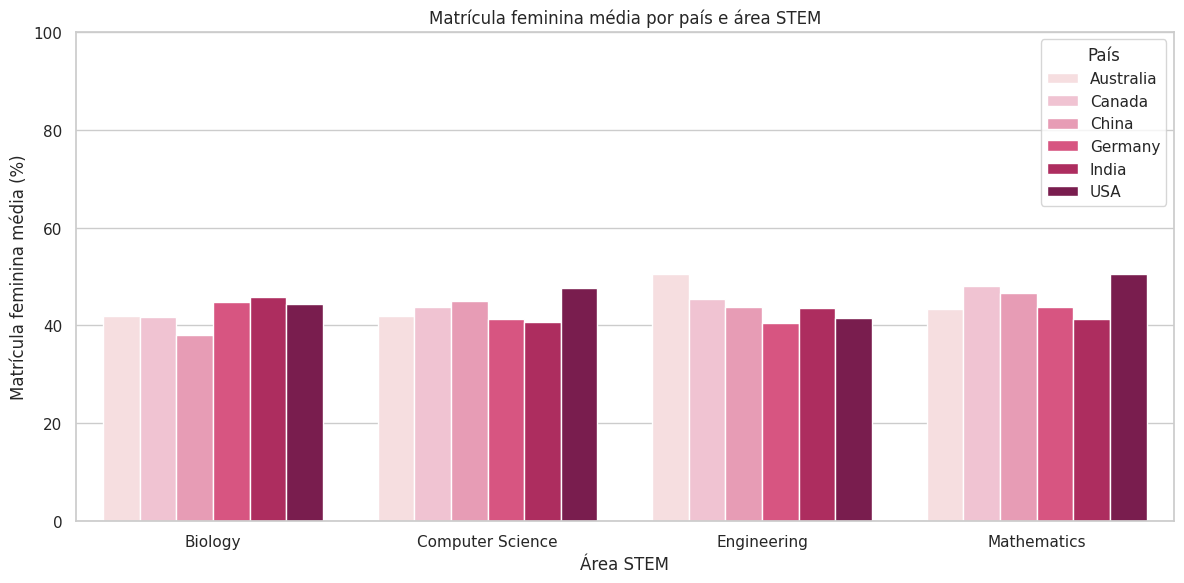

In [ ]:
medias = (ds.groupby(["STEM Fields", "Country"])["Female Enrollment (%)"].mean().reset_index())

maior_media = medias.groupby("STEM Fields")["Female Enrollment (%)"].transform("max")

vencedores = medias[medias["Female Enrollment (%)"] == maior_media]

print("Países com maior matrícula feminina média por área:")
print(vencedores.round(2).to_string(index=False))

sns.set_style("whitegrid")

sns.set_context("notebook")

plt.figure(figsize=(12, 6))


sns.barplot(
    data=medias,
    x="STEM Fields",
    y="Female Enrollment (%)",
    hue="Country",
    palette=[
         "#FADADD",
        "#F8BBD0",
        "#F48FB1",
        "#EC407A",
        "#C2185B",
        "#880E4F"
    ]
)

plt.title("Matrícula feminina média por país e área STEM")
plt.xlabel("Área STEM")
plt.ylabel("Matrícula feminina média (%)")

plt.ylim(0, 100)

plt.legend(title="País")

plt.tight_layout()
plt.show()



2- Como o índice de igualdade de gênero se distribui em cada área STEM?

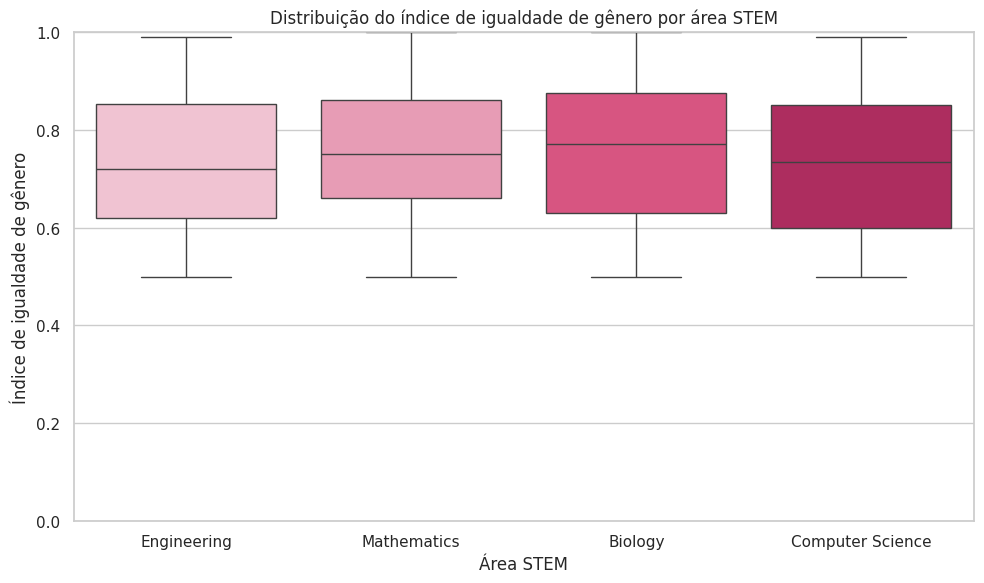

In [ ]:
sns.set_style("whitegrid")
sns.set_context("notebook")

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=ds,
    x="STEM Fields",
    y="Gender Gap Index",
    hue="STEM Fields",
    dodge=False,
    palette=[
        "#F8BBD0",
        "#F48FB1",
        "#EC407A",
        "#C2185B"
    ]
)

plt.title("Distribuição do índice de igualdade de gênero por área STEM")
plt.xlabel("Área STEM")
plt.ylabel("Índice de igualdade de gênero")
plt.ylim(0, 1)

plt.legend([], [], frameon=False)

plt.tight_layout()
plt.show()

3-  Quais combinações de país e área apresentam os menores índices médios de igualdade de gênero?

Combinações ordenadas do menor índice médio para o maior:
  Country      STEM Fields  Gender Gap Index
      USA Computer Science             0.674
    India Computer Science             0.685
    China          Biology             0.694
   Canada      Engineering             0.712
Australia Computer Science             0.712
      USA          Biology             0.725
   Canada      Mathematics             0.729
    China      Engineering             0.731
      USA      Mathematics             0.733
      USA      Engineering             0.740
Australia      Engineering             0.742
  Germany      Engineering             0.743
  Germany          Biology             0.759
    India      Engineering             0.760
  Germany Computer Science             0.762
Australia      Mathematics             0.764
    India          Biology             0.765
    India      Mathematics             0.766
    China Computer Science             0.774
    China      Mathematics             0.7

/tmp/ipykernel_824/2015473251.py:19: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  sns.barplot(


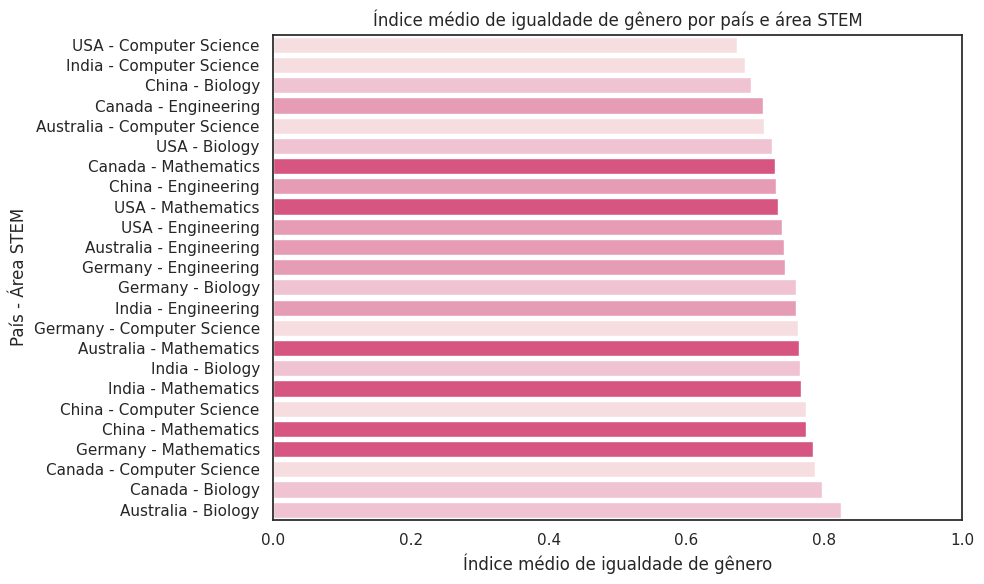

In [25]:
medias_indice = (ds.groupby(["Country", "STEM Fields"])["Gender Gap Index"].mean().reset_index())

menores_indices = medias_indice.sort_values("Gender Gap Index")

print("Combinações ordenadas do menor índice médio para o maior:")
print(menores_indices.round(3).to_string(index=False))

tabela = medias_indice.pivot(
    index="Country",
    columns="STEM Fields",
    values="Gender Gap Index"
)

sns.set_style("white")
sns.set_context("notebook")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=menores_indices,
    x="Gender Gap Index",
    y=menores_indices["Country"] + " - " + menores_indices["STEM Fields"],
    hue=menores_indices["STEM Fields"],
    palette=[
        "#FADADD",
        "#F8BBD0",
        "#F48FB1",
        "#EC407A",
        "#D81B60",
        "#AD1457"
    ],
    legend=False
)

plt.title("Índice médio de igualdade de gênero por país e área STEM")
plt.xlabel("Índice médio de igualdade de gênero")
plt.ylabel("País - Área STEM")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

4- Qual país apresenta o maior equilíbrio nos percentuais médios de matrícula feminina entre as quatro áreas STEM?

País com maior equilíbrio: Germany
Diferença entre as médias: 4.322514619883044 pontos percentuais


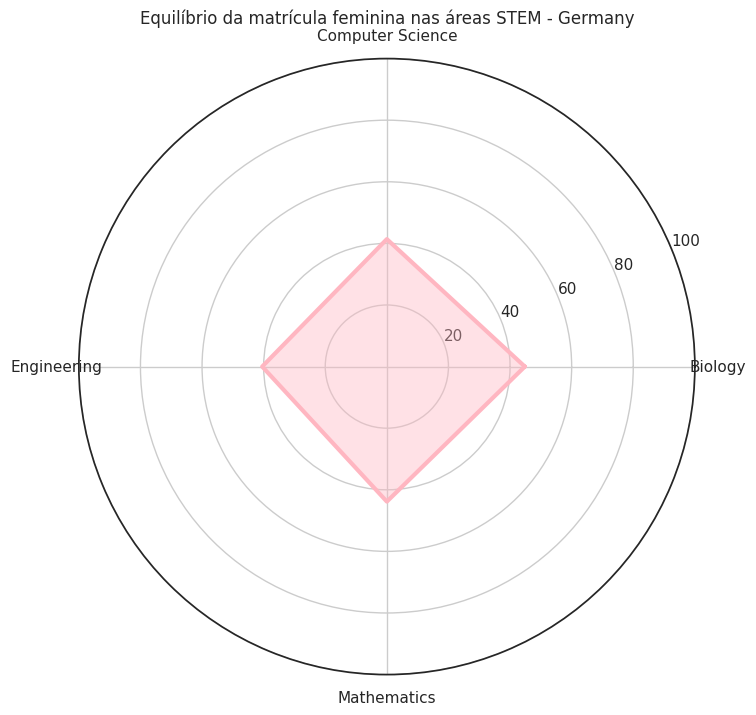

In [ ]:
grupo = ds.groupby(['Country', 'STEM Fields'])

medias = grupo['Female Enrollment (%)'].mean()

quantidade_areas = medias.groupby('Country').count()

paises_completos = quantidade_areas[quantidade_areas == 4].index

medias = medias.loc[paises_completos]

grupo_pais = medias.groupby('Country')

diferenca = grupo_pais.max() - grupo_pais.min()

pais = diferenca.idxmin()

menor = diferenca.min()

print('País com maior equilíbrio:', pais)
print('Diferença entre as médias:', menor, 'pontos percentuais')

dados_pais = medias.loc[pais]

areas = dados_pais.index.tolist()
valores = dados_pais.tolist()

angulos = np.linspace(0, 2*np.pi, len(areas), endpoint=False).tolist()

angulos += angulos[:1]
valores += valores[:1]

plt.figure(figsize=(8, 8))
plt.subplot(111, polar=True)

plt.plot(angulos, valores, color='lightpink', linewidth=3)

plt.fill(angulos, valores, color='lightpink', alpha=0.4)

plt.xticks(angulos[:-1], areas)

plt.ylim(0, 100)

plt.title('Equilíbrio da matrícula feminina nas áreas STEM - ' + pais, pad=25)

plt.show()

5- Qual área apresentou o maior crescimento do percentual médio de matrícula feminina entre 2000 e 2023?

Área com maior crescimento: Computer Science
Crescimento: 0.28000000000000114 pontos percentuais
STEM Fields
Biology             -8.055556
Computer Science     0.280000
Engineering        -14.913333
Mathematics         -1.860000
Name: Female Enrollment (%), dtype: float64


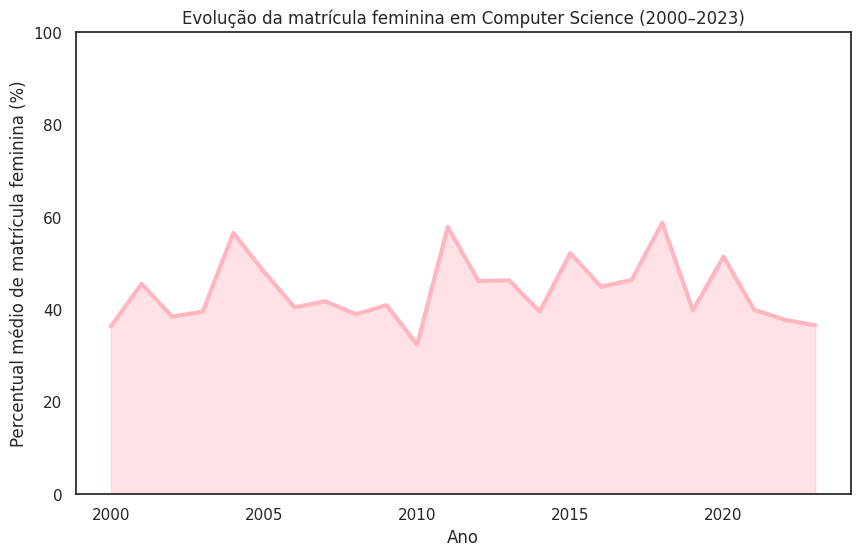

In [ ]:
grupo = ds.groupby(['Year', 'STEM Fields'])

medias = grupo['Female Enrollment (%)'].mean()

media_2000 = medias.loc[2000]

media_2023 = medias.loc[2023]

crescimento = media_2023 - media_2000

area = crescimento.idxmax()

maior = crescimento.max()

print('Área com maior crescimento:', area)
print('Crescimento:', maior, 'pontos percentuais')

print(crescimento)

dados_area = ds[ds['STEM Fields'] == area]

evolucao = dados_area.groupby('Year')['Female Enrollment (%)'].mean()

evolucao = evolucao[(evolucao.index >= 2000) & (evolucao.index <= 2023)]

plt.figure(figsize=(10, 6))

plt.plot(evolucao.index, evolucao.values,
         color='lightpink', linewidth=3)

plt.fill_between(evolucao.index, evolucao.values,
                 color='lightpink', alpha=0.4)

plt.title('Evolução da matrícula feminina em ' + area + ' (2000–2023)')

plt.xlabel('Ano')

plt.ylabel('Percentual médio de matrícula feminina (%)')

plt.ylim(0, 100)

plt.show()

6- Qual é a tendência do índice médio de igualdade de gênero ao longo dos anos em cada país?

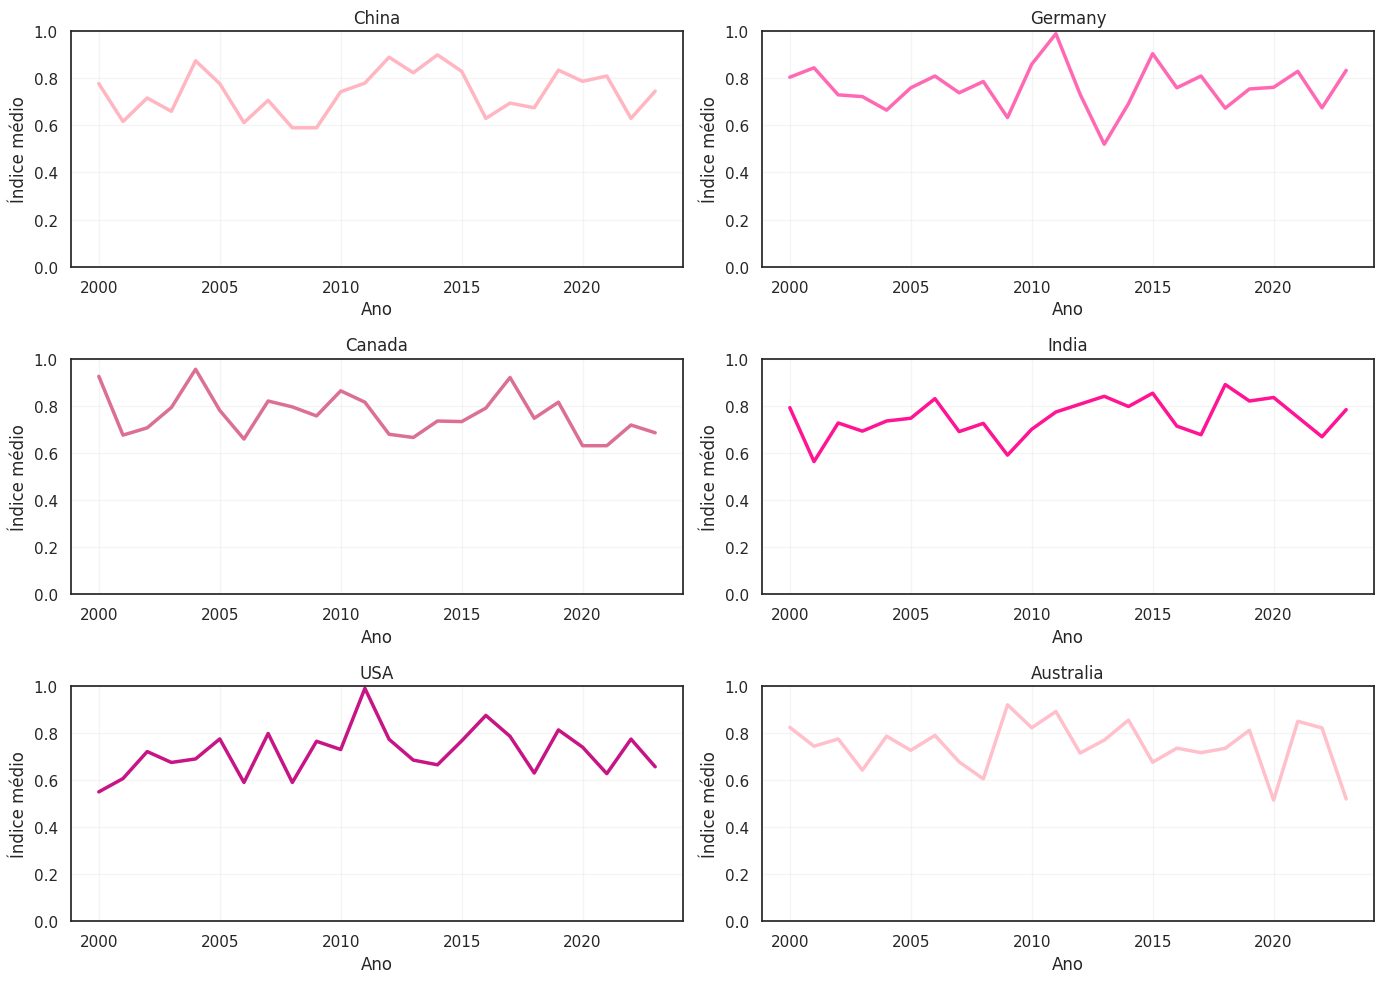

In [ ]:
grupo = ds.groupby(['Country', 'Year'])

medias = grupo['Gender Gap Index'].mean()

paises = ds['Country'].unique()

plt.figure(figsize=(14, 10))

cores = ['lightpink', 'hotpink', 'palevioletred',
         'deeppink', 'mediumvioletred', 'pink']

for i in range(len(paises)):

    pais = paises[i]

    dados_pais = medias.loc[pais]

    plt.subplot(3, 2, i + 1)

    plt.plot(dados_pais.index, dados_pais.values,
             color=cores[i], linewidth=2.5)

    plt.title(pais)

    plt.xlabel('Ano')
    plt.ylabel('Índice médio')

    plt.ylim(0, 1)

    plt.grid(True, alpha=0.2)

plt.tight_layout()

plt.show()



7- Nos Estados Unidos, entre 2010 e 2023, qual é a tendência da matrícula feminina em Ciência da Computação e em quais anos a média ficou abaixo de 40%?

Média de matrícula feminina por ano: Year
2012    62.85
2014    28.70
2015    32.00
2017    53.40
2019    59.50
2020    67.20
2023    32.40
Name: Female Enrollment (%), dtype: float64
Anos com média abaico de 40%:
Year
2014    28.7
2015    32.0
2023    32.4
Name: Female Enrollment (%), dtype: float64


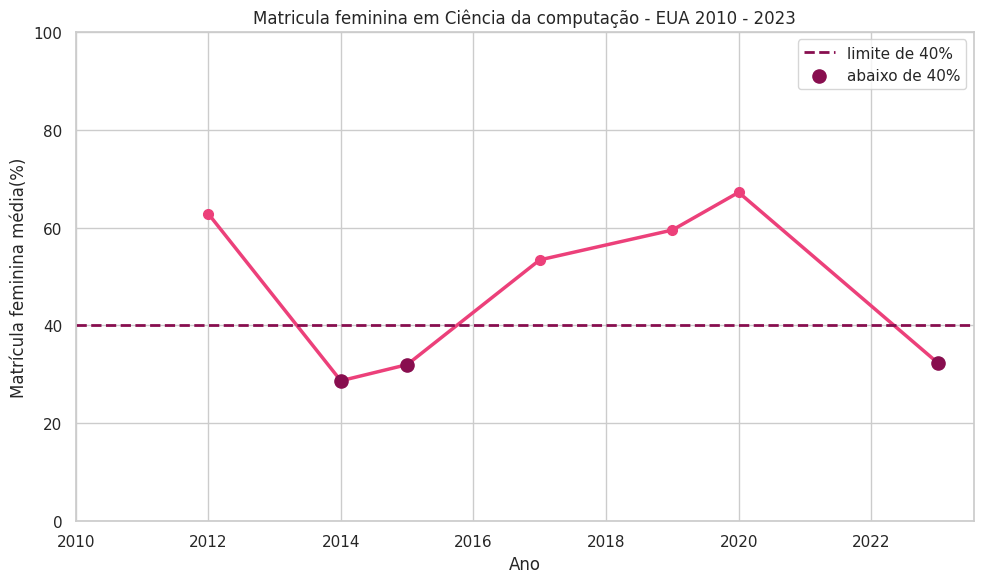

In [20]:
dados = ds[(ds['Country'] == 'USA') &
           (ds['STEM Fields'] == 'Computer Science') &
           (ds['Year'] >= 2010) &
           (ds['Year'] <= 2023)]

medias = dados.groupby('Year')['Female Enrollment (%)'].mean()

abaixo_40 = medias[medias < 40]
print('Média de matrícula feminina por ano:', medias.round(2))

print('Anos com média abaico de 40%:')
print(abaixo_40.round(2))

sns.set_style('whitegrid')
sns.set_context('notebook')

plt.figure(figsize = (10, 6))
plt.plot(
    medias.index,
    medias.values,
    color = '#EC407A',
    linewidth = 2.5,
    marker = 'o',
    markersize = 7
)

plt.axhline(
    y = 40,
    color = '#880E4F',
    linestyle = '--',
    linewidth = 2,
    label = 'limite de 40%'
)

plt.scatter(
    abaixo_40.index,
    abaixo_40.values,
    color = '#880E4F',
    s = 90,
    zorder = 3,
    label = 'abaixo de 40%'
)

plt.title('Matricula feminina em Ciência da computação - EUA 2010 - 2023')
plt.xlabel('Ano')
plt.ylabel('Matrícula feminina média(%)')

plt.ylim(0,100)
plt.xticks(range(2010, 2024, 2))

plt.legend()
plt.tight_layout()

8- Qual é o índice médio de igualdade de gênero na área de Engenharia em cada país no ano de 2023?

Índice médio de igualdade de gênero em Engenharia 2023:
Country  Gender Gap Index
  India             0.940
    USA             0.890
  China             0.685
 Canada             0.600


/tmp/ipykernel_824/399270332.py:23: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  sns.barplot(


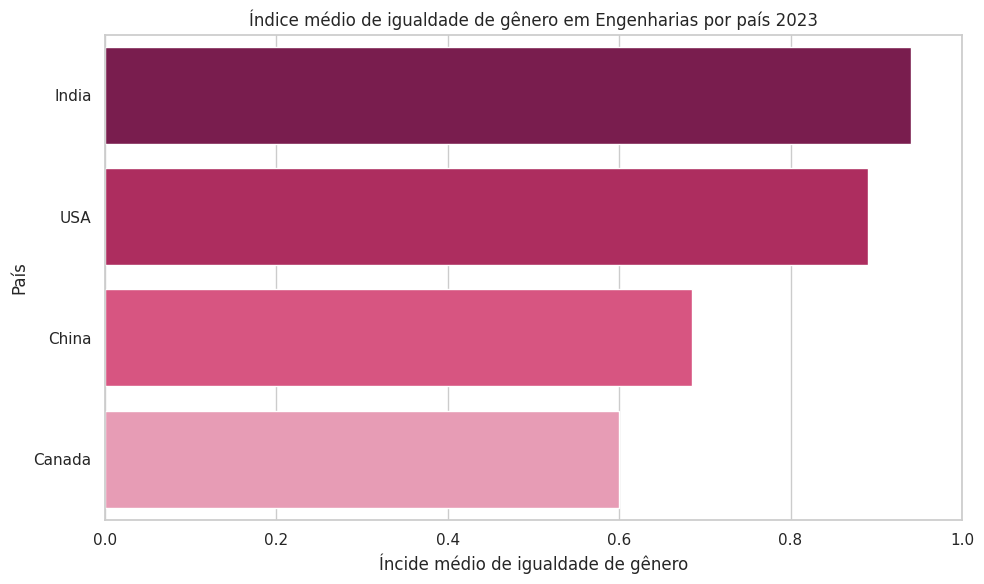

In [9]:
dados = ds[(ds['STEM Fields'] == 'Engineering') & (ds['Year'] == 2023)]

medias = (
    dados.groupby('Country')['Gender Gap Index'].mean().reset_index()
)

medias = medias.sort_values(
    'Gender Gap Index',
    ascending = False
)

print('Índice médio de igualdade de gênero em Engenharia 2023:')
print(medias.round(3).to_string(index = False))

sns.set_style('whitegrid')
sns.set_context('notebook')

plt.figure(figsize = (10, 6))

sns.barplot(
    data = medias,
    x = 'Gender Gap Index',
    y = 'Country',
    hue = 'Country',
    palette = [
        '#880E4F',
        '#C2185B',
        '#EC407A',
        '#F48FB1',
        '#F8BBD0',
        '#FADADD'
    ],
    legend = False
)

plt.title('Índice médio de igualdade de gênero em Engenharias por país 2023')
plt.xlabel('Índice médio de igualdade de gênero')
plt.ylabel('País')
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

9- Quais são os coeficientes de correlação entre o percentual de matrícula feminina, o percentual de conclusão feminina e o índice de igualdade de gênero?

coeficientes de correlação entre as variáveis:
                            Female Enrollment (%)  Female Graduation Rate (%)  \
Female Enrollment (%)                       1.000                       0.016   
Female Graduation Rate (%)                  0.016                       1.000   
Gender Gap Index                           -0.081                       0.027   

                            Gender Gap Index  
Female Enrollment (%)                 -0.081  
Female Graduation Rate (%)             0.027  
Gender Gap Index                       1.000  


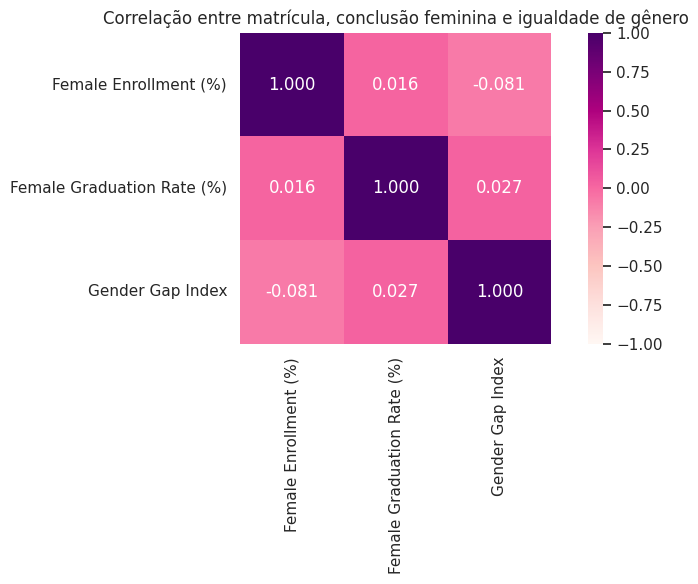

In [15]:
variaveis = ds[['Female Enrollment (%)', 'Female Graduation Rate (%)', 'Gender Gap Index']]

correlacao = variaveis.corr()
print('coeficientes de correlação entre as variáveis:')
print(correlacao.round(3))

sns.set_style('white')
sns.set_context('notebook')

plt.figure(figsize = (9, 6))

sns.heatmap(
    correlacao,
    annot = True,
    fmt = '.3f',
    cmap = 'RdPu',
    vmin = -1,
    vmax = 1,
    center = 0,
    square = True
)

plt.title('Correlação entre matrícula, conclusão feminina e igualdade de gênero')
plt.tight_layout()
plt.show()

10-  Como o percentual médio de matrícula feminina em Engenharia, Ciência da Computação, Matemática e Biologia se compara entre Estados Unidos, China e Índia no período de 2015 a 2023?

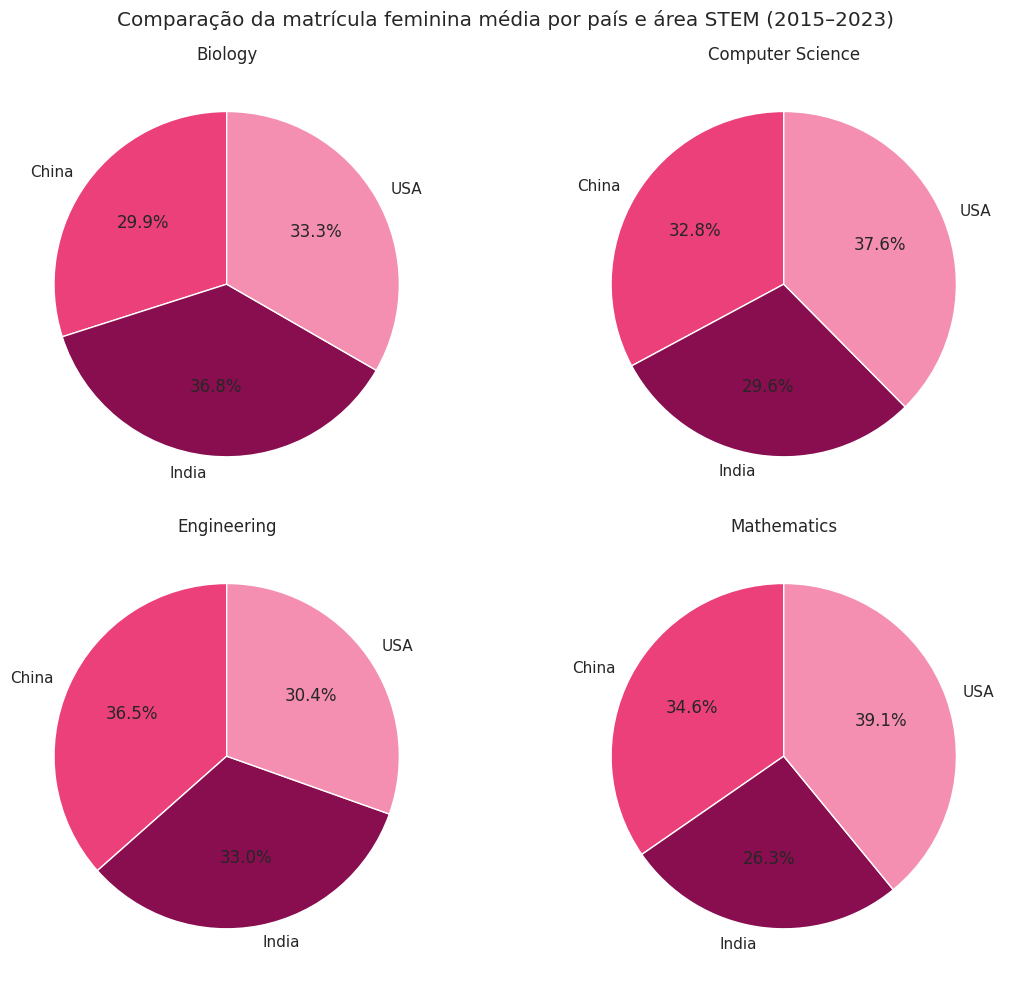

In [22]:
dados = ds[
    (ds['Country'].isin(['USA', 'China', 'India'])) & (ds['Year'] >= 2015) & (ds['Year'] <= 2023)
]

medias = (
    dados.groupby(['Country', 'STEM Fields'])
    ['Female Enrollment (%)']
    .mean()
    .reset_index()
)

cores = [
    '#EC407A',
    '#880E4F',
    '#F48FB1'
    ]

areas = medias['STEM Fields'].unique()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, area in enumerate(areas):
    dados_area = medias[medias['STEM Fields'] == area]

    axes[i].pie(
        dados_area['Female Enrollment (%)'],
        labels=dados_area['Country'],
        autopct='%1.1f%%',
        colors=cores,
        startangle=90
    )

    axes[i].set_title(area)

fig.suptitle(
    'Comparação da matrícula feminina média por país e área STEM (2015–2023)'
)

plt.tight_layout()
plt.show()